In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns

In [2]:
df = pd.read_csv('Nassau Candy Distributor.csv')

In [3]:
df.head(5)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90


In [4]:
df.describe()

,Row ID,Customer ID,Sales,Units,Gross Profit,Cost
count,10194.000000,10194.000000,10194.000000,10194.000000,10194.000000,10194.000000
mean,5097.500000,134468.961154,13.908537,3.791838,9.166451,4.742087
std,2942.898656,20231.483007,11.341020,2.228317,6.643740,5.061647
min,1.000000,100006.000000,1.250000,1.000000,0.250000,0.600000
25%,2549.250000,117212.000000,7.200000,2.000000,4.900000,2.400000
50%,5097.500000,133550.000000,10.800000,3.000000,7.470000,3.600000
75%,7645.750000,152051.000000,18.000000,5.000000,12.250000,5.700000
max,10194.000000,192314.000000,260.000000,14.000000,130.000000,130.000000


In [5]:
df.isnull().sum()

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Division          0
Region            0
Product ID        0
Product Name      0
Sales             0
Units             0
Gross Profit      0
Cost              0
dtype: int64

In [6]:
df['Gross Margin (%)'] = (df['Gross Profit'] / df['Sales']) * 100

df['Profit per Unit'] = df['Gross Profit'] / df['Units']

df[['Product Name', 'Sales', 'Gross Profit', 'Units', 'Gross Margin (%)', 'Profit per Unit']].head()

,Product Name,Sales,Gross Profit,Units,Gross Margin (%),Profit per Unit
0,Wonka Bar - Milk Chocolate,6.50,4.22,2,64.923077,2.11
1,Wonka Bar - Triple Dazzle Caramel,7.50,4.90,2,65.333333,2.45
2,Wonka Bar - Nutty Crunch Surprise,10.47,7.47,3,71.346705,2.49
3,Wonka Bar -Scrumdiddlyumptious,10.80,7.50,3,69.444444,2.50
4,Wonka Bar - Triple Dazzle Caramel,11.25,7.35,3,65.333333,2.45


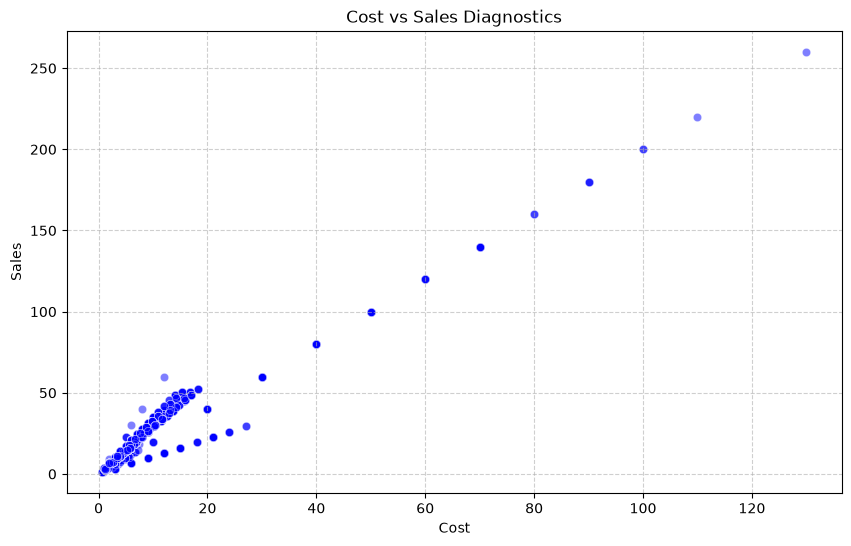

In [7]:
# Cost vs Sales Scatter Plot 
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Cost', y='Sales', alpha=0.5, color='blue')

plt.title('Cost vs Sales Diagnostics')
plt.xlabel('Cost')
plt.ylabel('Sales')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

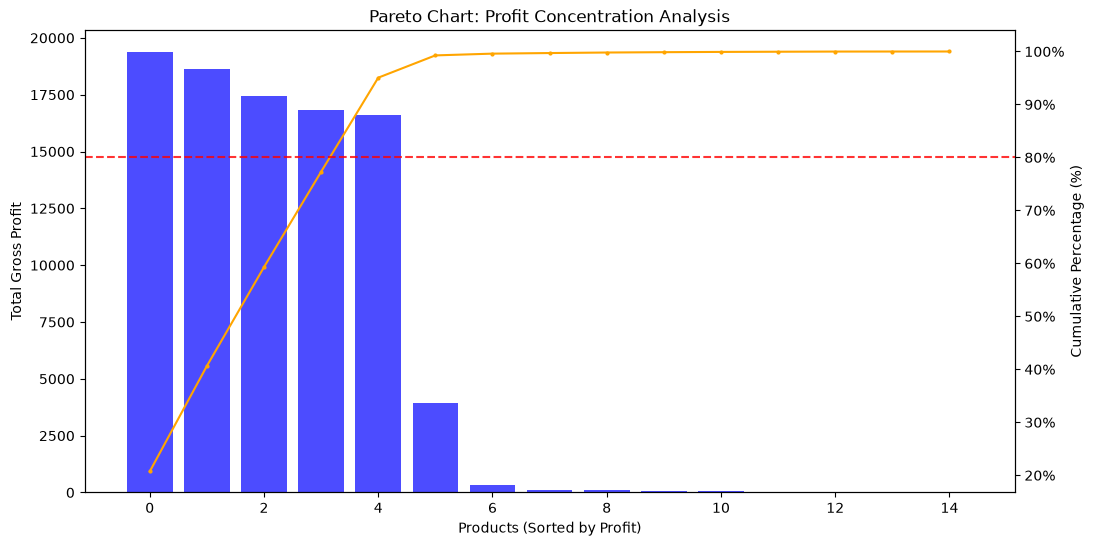

In [8]:
product_profit = df.groupby('Product Name')['Gross Profit'].sum().sort_values(ascending=False).reset_index()

# 2. Cumulative Percentage 
product_profit['Cumulative Percentage'] = product_profit['Gross Profit'].cumsum() / product_profit['Gross Profit'].sum() * 100

# 3. Pareto Chart 
fig, ax = plt.subplots(figsize=(12, 6))

# Bar chart
ax.bar(product_profit.index, product_profit['Gross Profit'], color='blue', alpha=0.7)
ax.set_ylabel('Total Gross Profit')
ax.set_xlabel('Products (Sorted by Profit)')

# Bar chart
ax2 = ax.twinx()
ax2.plot(product_profit.index, product_profit['Cumulative Percentage'], color='orange', marker='.', ms=4)
ax2.yaxis.set_major_formatter(PercentFormatter())
ax2.set_ylabel('Cumulative Percentage (%)')

ax2.axhline(80, color='red', linestyle='dashed', alpha=0.8)

plt.title('Pareto Chart: Profit Concentration Analysis')
plt.show()

    Division      Sales  Gross Profit  Average Margin (%)
0  Chocolate  131692.90      88824.62           67.448298
2      Sugar     427.48        284.73           66.606625
1      Other    9663.25       4333.45           44.844643


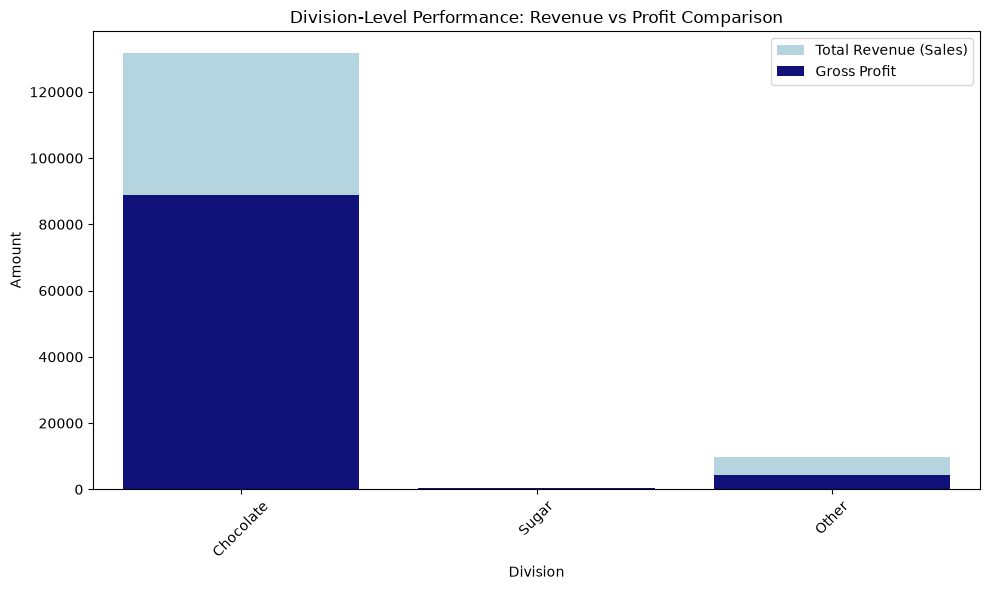

In [9]:
# Division-Level Performance: Aggregating Revenue (Sales) and Profit by Division
division_performance = df.groupby('Division')[['Sales', 'Gross Profit']].sum().reset_index()

# Calculating Average Margin by Division
division_performance['Average Margin (%)'] = (division_performance['Gross Profit'] / division_performance['Sales']) * 100

# Sorting by Average Margin to see which division is most efficient
division_performance = division_performance.sort_values(by='Average Margin (%)', ascending=False)

# Display the grouped data
print(division_performance)

# Plotting Revenue vs Profit comparison by Division
plt.figure(figsize=(10, 6))

# Plotting Sales (Revenue)
sns.barplot(data=division_performance, x='Division', y='Sales', color='lightblue', label='Total Revenue (Sales)')

# Plotting Gross Profit on top/alongside
sns.barplot(data=division_performance, x='Division', y='Gross Profit', color='darkblue', label='Gross Profit')

plt.title('Division-Level Performance: Revenue vs Profit Comparison')
plt.ylabel('Amount')
plt.xlabel('Division')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
# 1. Product-level 
product_leaderboard = df.groupby('Product Name').agg({
    'Sales': 'sum', 
    'Gross Profit': 'sum', 
    'Units': 'sum'
}).reset_index()

# 2. Gross Margin (%) काढणे
product_leaderboard['Gross Margin (%)'] = (product_leaderboard['Gross Profit'] / product_leaderboard['Sales']) * 100

# 3. High-Profit / High-Margin Products 
top_products = product_leaderboard.sort_values(by='Gross Profit', ascending=False).head(5)
print("--- Top 5 High-Profit Products ---")
print(top_products[['Product Name', 'Sales', 'Gross Profit', 'Gross Margin (%)']])

print("\n" + "="*50 + "\n")

# 4. Low-Margin / Margin-Risk Products 
risk_products = product_leaderboard[product_leaderboard['Sales'] > 0].sort_values(by='Gross Margin (%)', ascending=True).head(5)
print("--- Top 5 Margin-Risk Products ---")
print(risk_products[['Product Name', 'Sales', 'Gross Profit', 'Gross Margin (%)']])

--- Top 5 High-Profit Products ---
                         Product Name     Sales  Gross Profit  \
13     Wonka Bar -Scrumdiddlyumptious  27874.80      19357.50   
12  Wonka Bar - Triple Dazzle Caramel  28485.00      18610.20   
10         Wonka Bar - Milk Chocolate  26867.75      17443.37   
11  Wonka Bar - Nutty Crunch Surprise  23574.95      16819.95   
9           Wonka Bar - Fudge Mallows  24890.40      16593.60   

    Gross Margin (%)  
13         69.444444  
12         65.333333  
10         64.923077  
11         71.346705  
9          66.666667  


--- Top 5 Margin-Risk Products ---
         Product Name    Sales  Gross Profit  Gross Margin (%)
4           Kazookles  1205.75         92.75          7.692308
2             Fun Dip    12.00          4.80         40.000000
7               Nerds    15.00          7.00         46.666667
8           SweeTARTS    61.50         28.70         46.666667
6  Lickable Wallpaper  7860.00       3930.00         50.000000


In [12]:
%%writefile app.py
import streamlit as st
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

# 1. Page Configuration
st.set_page_config(page_title="Nassau Candy Profitability Dashboard", layout="wide")
st.title("🍫 Nassau Candy: Profitability & Margin Performance")

# 2. Load Data 
@st.cache_data
def load_data():
    
    try:
        df = pd.read_csv('Nassau Candy Distributor.csv') 
        
        
        if 'Gross Margin (%)' not in df.columns:
            df['Gross Margin (%)'] = (df['Gross Profit'] / df['Sales']) * 100
        return df
    except FileNotFoundError:
        st.error("Please make sure your CSV file is in the same folder and named correctly!")
        return pd.DataFrame()

df = load_data()

if not df.empty:
    # 3. Sidebar - User Capabilities (Filters)
    st.sidebar.header("📊 Dashboard Filters")
    
    # Product Search
    search_query = st.sidebar.text_input("🔍 Product Search", "")
    
    # Division Filter
    divisions = df['Division'].unique().tolist() if 'Division' in df.columns else []
    selected_divisions = st.sidebar.multiselect("🏢 Filter by Division", divisions, default=divisions)
    
    # Margin Threshold Slider
    margin_threshold = st.sidebar.slider("⚠️ Margin Risk Threshold (%)", min_value=0, max_value=100, value=20)
    
    # 4. Apply Filters to Data
    filtered_df = df.copy()
    
    if search_query:
        filtered_df = filtered_df[filtered_df['Product Name'].str.contains(search_query, case=False, na=False)]
        
    if selected_divisions and 'Division' in df.columns:
        filtered_df = filtered_df[filtered_df['Division'].isin(selected_divisions)]
        
    # 5. Dashboard Layout (Top Metrics)
    col1, col2, col3 = st.columns(3)
    col1.metric("Total Revenue (Sales)", f"${filtered_df['Sales'].sum():,.2f}")
    col2.metric("Total Gross Profit", f"${filtered_df['Gross Profit'].sum():,.2f}")
    overall_margin = (filtered_df['Gross Profit'].sum() / filtered_df['Sales'].sum()) * 100 if filtered_df['Sales'].sum() > 0 else 0
    col3.metric("Overall Average Margin", f"{overall_margin:.2f}%")
    
    st.divider()

    # 6. Row 1: Leaderboards
    col1, col2 = st.columns(2)
    with col1:
        st.subheader("🏆 Top High-Profit Products")
        top_products = filtered_df.groupby('Product Name')[['Sales', 'Gross Profit', 'Gross Margin (%)']].sum().sort_values(by='Gross Profit', ascending=False).head(5)
        st.dataframe(top_products, use_container_width=True)
        
    with col2:
        st.subheader("⚠️ Margin Risk Products (Below Threshold)")
        # Filtering based on user's slider input
        risk_products = filtered_df[(filtered_df['Sales'] > 0) & (filtered_df['Gross Margin (%)'] < margin_threshold)]
        risk_products = risk_products.groupby('Product Name')[['Sales', 'Gross Profit', 'Gross Margin (%)']].mean().sort_values(by='Gross Margin (%)', ascending=True).head(5)
        st.dataframe(risk_products, use_container_width=True)

    st.divider()

    # 7. Row 2: Visualizations (Scatter Plot & Pareto)
    col3, col4 = st.columns(2)
    
    with col3:
        st.subheader("📈 Cost vs Sales Diagnostics")
        fig, ax = plt.subplots(figsize=(8, 5))
        sns.scatterplot(data=filtered_df, x='Cost', y='Sales', alpha=0.6, color='blue', ax=ax)
        plt.grid(True, linestyle='--', alpha=0.5)
        st.pyplot(fig)
        
    with col4:
        st.subheader("📊 Profit Concentration (Pareto Analysis)")
        product_profit = filtered_df.groupby('Product Name')['Gross Profit'].sum().sort_values(ascending=False).reset_index()
        product_profit['Cumulative Percentage'] = product_profit['Gross Profit'].cumsum() / product_profit['Gross Profit'].sum() * 100
        
        fig2, ax1 = plt.subplots(figsize=(8, 5))
        ax1.bar(product_profit.index, product_profit['Gross Profit'], color='darkblue', alpha=0.7)
        ax2 = ax1.twinx()
        ax2.plot(product_profit.index, product_profit['Cumulative Percentage'], color='orange', marker='.')
        ax2.yaxis.set_major_formatter(PercentFormatter())
        ax2.axhline(80, color='red', linestyle='dashed', alpha=0.8)
        
        ax1.set_xlabel("Products")
        ax1.set_ylabel("Gross Profit")
        st.pyplot(fig2)

Overwriting app.py


In [13]:
%%writefile requirements.txt
streamlit 
pandas 
matplotlib
seaborn 

Writing requirements.txt
